In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from rain2loss.gis import catchment_polygon
from rain2loss.lamah import load_attributes
from rain2loss.paths import DATA_PROCESSED
from rain2loss.terrain import (catchment_polygon_from_mask, cell_area_km2, delineate_catchment,
                               flow_direction_and_accumulation, height_above_nearest_drainage,
                               load_conditioned_dem, stream_network)

GAUGE_ID = 824
attrs = load_attributes()
DEM = DATA_PROCESSED / "dem_3035_bilinear.tif"          # made in week 4

cells raised by conditioning: 16911  deepest fill: 33.5 m


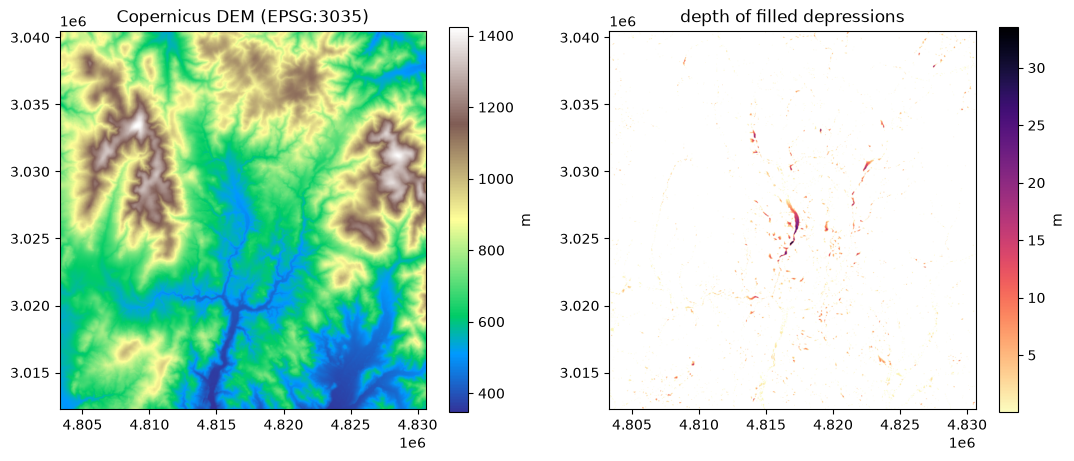

In [2]:
grid, dem, conditioned = load_conditioned_dem(str(DEM))
filled = conditioned - dem
print("cells raised by conditioning:", int((filled > 0.01).sum()), " deepest fill: %.1f m" % filled.max())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im0 = axes[0].imshow(dem, extent=grid.extent, cmap="terrain")
plt.colorbar(im0, ax=axes[0], label="m")
axes[0].set_title("Copernicus DEM (EPSG:3035)")
im1 = axes[1].imshow(np.where(filled > 0.01, filled, np.nan), extent=grid.extent, cmap="magma_r")
plt.colorbar(im1, ax=axes[1], label="m")
axes[1].set_title("depth of filled depressions")
plt.show()

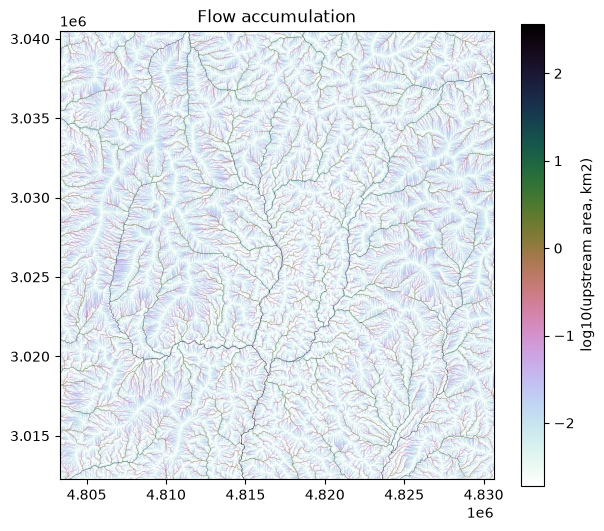

In [3]:
fdir, acc = flow_direction_and_accumulation(grid, conditioned)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.log10(acc * cell_area_km2(grid) + 1e-3), extent=grid.extent, cmap="cubehelix_r")
plt.colorbar(im, label="log10(upstream area, km2)")
ax.set_title("Flow accumulation")
plt.show()

In [4]:
gauge_x, gauge_y = attrs.loc[GAUGE_ID, ["lon", "lat"]]            # EPSG:3035 metres
catch, (snap_x, snap_y) = delineate_catchment(grid, fdir, acc, gauge_x, gauge_y, min_area_km2=100)
print(f"gauge moved {np.hypot(snap_x - gauge_x, snap_y - gauge_y):.0f} m to the river")

dem_poly = catchment_polygon_from_mask(grid, catch)
lamah_poly = catchment_polygon(GAUGE_ID, crs="EPSG:3035")
a_dem = dem_poly.area.iloc[0] / 1e6
a_lamah = lamah_poly.area.iloc[0] / 1e6
a_gov = attrs.loc[GAUGE_ID, "area_gov"]
print(f"area: DEM {a_dem:.1f} km2, LamaH polygon {a_lamah:.1f} km2, official {a_gov:.1f} km2 "
      f"({100 * (a_dem / a_gov - 1):+.1f} %)")
overlap = gpd.overlay(dem_poly, lamah_poly, how="intersection").area.sum()
union = gpd.overlay(dem_poly, lamah_poly, how="union").area.sum()
print(f"intersection over union: {overlap / union:.3f}")
dem_poly.to_file(DATA_PROCESSED / "catchment_824_dem.gpkg")

gauge moved 50 m to the river
area: DEM 351.4 km2, LamaH polygon 351.0 km2, official 349.8 km2 (+0.5 %)
intersection over union: 0.978


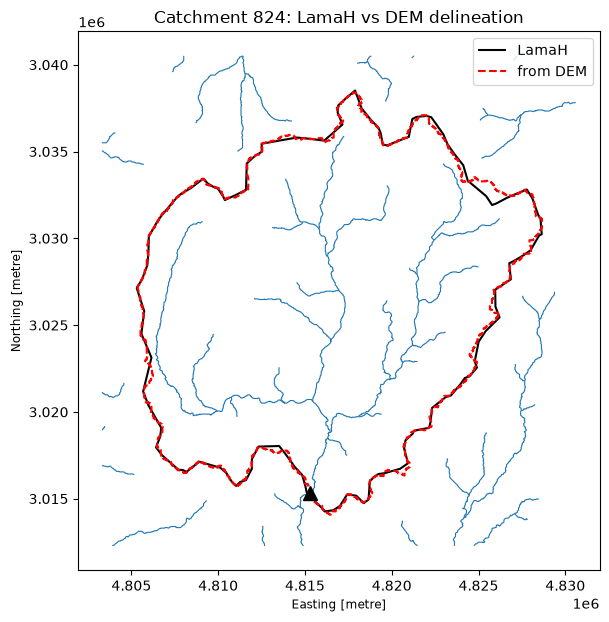

In [5]:
streams = stream_network(grid, fdir, acc, min_area_km2=5)
fig, ax = plt.subplots(figsize=(7, 7))
lamah_poly.boundary.plot(ax=ax, color="black", label="LamaH")
dem_poly.boundary.plot(ax=ax, color="red", linestyle="--", label="from DEM")
streams.plot(ax=ax, color="tab:blue", linewidth=0.8)
ax.plot(gauge_x, gauge_y, "k^", markersize=10)
ax.legend()
ax.set_title("Catchment 824: LamaH vs DEM delineation")
plt.show()
streams.to_file(DATA_PROCESSED / "streams_824.gpkg")

share of catchment with HAND < 2 m: 0.024
share of catchment with HAND < 5 m: 0.035
share of catchment with HAND < 10 m: 0.049


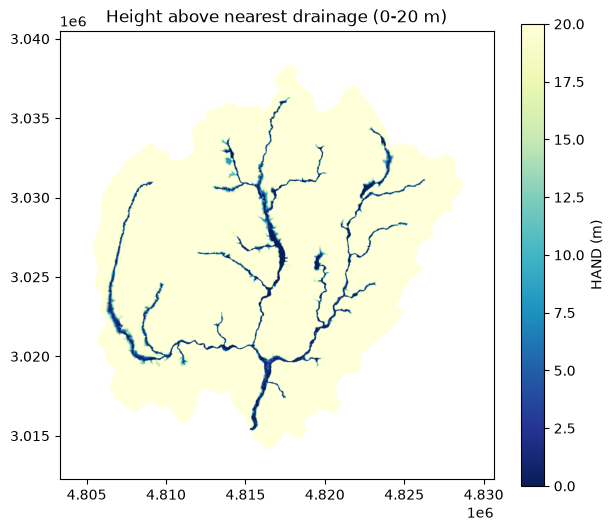

In [6]:
hand = height_above_nearest_drainage(grid, fdir, conditioned, acc, min_area_km2=5)
grid.to_raster(hand, str(DATA_PROCESSED / "hand_3035.tif"))
inside = np.asarray(catch)
for limit in [2, 5, 10]:
    print(f"share of catchment with HAND < {limit} m: {np.nanmean(hand[inside] < limit):.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.where(inside, hand, np.nan), extent=grid.extent, cmap="YlGnBu_r", vmin=0, vmax=20)
plt.colorbar(im, label="HAND (m)")
ax.set_title("Height above nearest drainage (0-20 m)")
plt.show()

In [7]:
elevations = np.asarray(dem)[inside]
print("DEM hypsometry: mean %.0f m, std %.0f m" % (elevations.mean(), elevations.std()))
zones_dem = np.percentile(elevations, [100 / 6, 50, 500 / 6]) - elevations.mean()
print("zone offsets from the DEM (m):", zones_dem.round(0))

DEM hypsometry: mean 754 m, std 198 m
zone offsets from the DEM (m): [-184.  -49.  209.]
